# Machine Learning Assignment 2
## Bank Term Deposit Subscription Prediction

The objective of this project is to develop and compare machine learning classification models for predicting whether a bank client will subscribe to a term deposit.

### Initial Dataset Exploration
This notebook starts with loading and understanding the UCI Bank Marketing dataset before preprocessing and model development.


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [22]:
# Load the Bank Marketing dataset
bank_data = pd.read_csv("data/bank-full.csv", sep=";")

print("Dataset Shape:", bank_data.shape)
bank_data.head()


Dataset Shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [23]:
# Review column names, data types and non-null counts
bank_data.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [24]:
# Check for missing values
missing_values = bank_data.isnull().sum()

print("Missing Values:")
print(missing_values)


Missing Values:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [25]:
# Check for duplicate records
duplicate_count = bank_data.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [26]:
# Review the target variable distribution
print("Target Distribution:")
print(bank_data["y"].value_counts())

print("\nTarget Distribution (%):")
print(bank_data["y"].value_counts(normalize=True) * 100)


Target Distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target Distribution (%):
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [27]:
# Identify categorical and numerical features
# Exclude the target column y from the feature lists
feature_data = bank_data.drop(columns=["y"])

categorical_features = feature_data.select_dtypes(include=["object"]).columns.tolist()
numerical_features = feature_data.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)


Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Numerical Features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


## 2. Data Preprocessing

In this section, the dataset is prepared for model development. The target variable is encoded, the data is divided into training and testing sets, and separate preprocessing steps are defined for numerical and categorical features.

In [30]:
## Check duplicates before cleaning

duplicate_count = bank_data.duplicated().sum()
print("Duplicate rows before cleaning:", duplicate_count)

if duplicate_count > 0:
    bank_data = bank_data.drop_duplicates().reset_index(drop=True)

print("Dataset shape after duplicate removal:", bank_data.shape)

Duplicate rows before cleaning: 0
Dataset shape after duplicate removal: (45211, 17)


In [31]:
## Separate features and target

X = bank_data.drop(columns=["y"])

y = bank_data["y"].map({
    "no": 0,
    "yes": 1
})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nEncoded target distribution:")
print(y.value_counts())

Feature matrix shape: (45211, 16)
Target shape: (45211,)

Encoded target distribution:
y
0    39922
1     5289
Name: count, dtype: int64


In [32]:
## Identify feature types
categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_features = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Numerical Features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Number of categorical features: 9
Number of numerical features: 7


In [33]:
## Train/test split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training feature shape: (36168, 16)
Testing feature shape: (9043, 16)

Training target distribution:
y
0    0.883018
1    0.116982
Name: proportion, dtype: float64

Testing target distribution:
y
0    0.883003
1    0.116997
Name: proportion, dtype: float64


In [35]:
## Create preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## 3. Model Development and Evaluation

Five classification models are developed and evaluated using the same training and testing data.

The following evaluation metrics are used:
- Accuracy
- AUC
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

In [36]:
## Import models, pipeline, and metrics
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

In [37]:
## Create one evaluation function
def evaluate_model(model_name, model, X_test, y_test):

    # Class predictions
    y_pred = model.predict(X_test)

    # Probability/decision scores for AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_score)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    mcc = matthews_corrcoef(y_test, y_pred)

    results = {
        "Model": model_name,
        "Accuracy": accuracy,
        "AUC": auc,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "MCC": mcc
    }

    return results, y_pred

### 3.1 Logistic Regression

Logistic Regression is used as the first classification model. The preprocessing and classifier are combined in a pipeline so that preprocessing is learned only from the training data.

In [38]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)
logistic_pipeline.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [39]:
## Evaluate Logistic Regression
logistic_results, logistic_pred = evaluate_model(
    "Logistic Regression",
    logistic_pipeline,
    X_test,
    y_test
)

logistic_results

{'Model': 'Logistic Regression',
 'Accuracy': 0.901249585314608,
 'AUC': np.float64(0.9055740146044154),
 'Precision': 0.6444833625218914,
 'Recall': 0.34782608695652173,
 'F1 Score': 0.4518109269490485,
 'MCC': np.float64(0.42605817794513523)}

In [40]:
## Show the results more clearly
logistic_results_df = pd.DataFrame([logistic_results])

logistic_results_df.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9012,0.9056,0.6445,0.3478,0.4518,0.4261


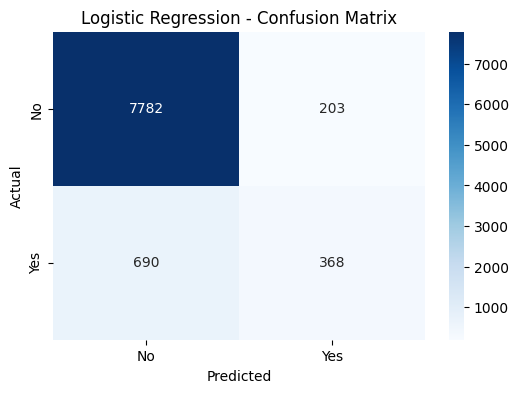

In [41]:
## Confusion Matrix
cm = confusion_matrix(y_test, logistic_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [42]:
## Classification report
print("Logistic Regression Classification Report:\n")

print(
    classification_report(
        y_test,
        logistic_pred,
        target_names=["No", "Yes"]
    )
)

Logistic Regression Classification Report:

              precision    recall  f1-score   support

          No       0.92      0.97      0.95      7985
         Yes       0.64      0.35      0.45      1058

    accuracy                           0.90      9043
   macro avg       0.78      0.66      0.70      9043
weighted avg       0.89      0.90      0.89      9043



### 3.2 Decision Tree

The Decision Tree classifier is trained using the same training and testing data. The model can capture non-linear relationships between the input features and the target variable.

In [43]:
## Adding the model
from sklearn.tree import DecisionTreeClassifier

decision_tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

decision_tree_pipeline.fit(X_train, y_train)

print("Decision Tree training completed.")

Decision Tree training completed.


In [44]:
## Evaluating the Decision Tree
decision_tree_results, decision_tree_pred = evaluate_model(
    "Decision Tree",
    decision_tree_pipeline,
    X_test,
    y_test
)

pd.DataFrame([decision_tree_results]).round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Decision Tree,0.8746,0.7015,0.4649,0.4754,0.4701,0.399


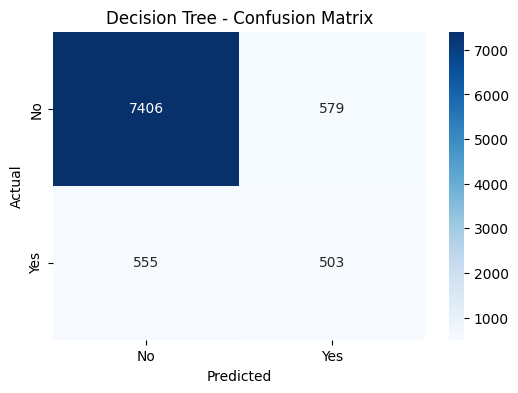

In [45]:
## Confusion matrix -Decision Tree
cm = confusion_matrix(y_test, decision_tree_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### 3.3 K-Nearest Neighbors

K-Nearest Neighbors classifies observations based on the classes of nearby observations in the transformed feature space. Numerical features are standardized before model training.

In [46]:
## Adding the model
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(
            n_neighbors=5
        ))
    ]
)

knn_pipeline.fit(X_train, y_train)

print("KNN training completed.")

KNN training completed.


In [47]:
## Evaluating the KNN Model
knn_results, knn_pred = evaluate_model(
    "K-Nearest Neighbors",
    knn_pipeline,
    X_test,
    y_test
)

pd.DataFrame([knn_results]).round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,K-Nearest Neighbors,0.8962,0.8277,0.599,0.3403,0.434,0.4001


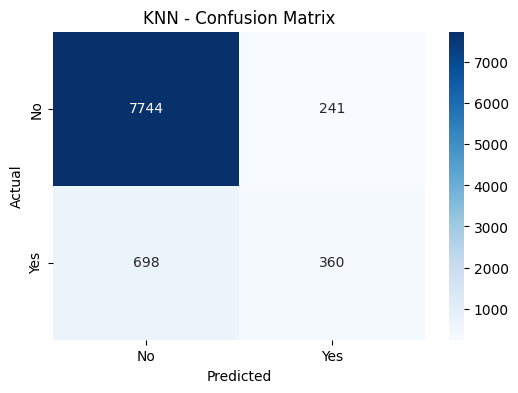

In [48]:
## Confusion matrix -KNN
cm = confusion_matrix(y_test, knn_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [49]:
## Comparing the first three models
initial_model_results = pd.DataFrame([
    logistic_results,
    decision_tree_results,
    knn_results
])

initial_model_results.round(4)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.9012,0.9056,0.6445,0.3478,0.4518,0.4261
1,Decision Tree,0.8746,0.7015,0.4649,0.4754,0.4701,0.3990
2,K-Nearest Neighbors,0.8962,0.8277,0.5990,0.3403,0.4340,0.4001
